# ROI_processing

In [45]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns

parent_dir = os.path.abspath(os.path.join(os.getcwd(), "../../src/troutpy_reproducibility"))
# Add parent directory to sys.path
sys.path.append(parent_dir)

from batch_running import *

In [11]:
import os
import pandas as pd

# Define the root directory
root_dir = "/media/sergio/Meninges/troutpy/rois"

# Initialize an empty list to hold individual metadata DataFrames
metadata_list = []

# List only first-level subdirectories
subfolders = [f.path for f in os.scandir(root_dir) if f.is_dir()]

for subfolder in subfolders:
    metadata_path = os.path.join(subfolder, "metadata.csv")
    if os.path.isfile(metadata_path):
        try:
            df = pd.read_csv(metadata_path)
            # Add subfolder name as a column
            metadata_list.append(df)
        except Exception as e:
            print(f"Failed to read {metadata_path}: {e}")

# Combine all metadata files into a single DataFrame
if metadata_list:
    combined_metadata = pd.concat(metadata_list, ignore_index=True)
    print("Combined metadata shape:", combined_metadata.shape)
else:
    print("No metadata.csv files found.")

Combined metadata shape: (10, 14)


In [38]:
combined_metadata.index = combined_metadata["sample_id"]

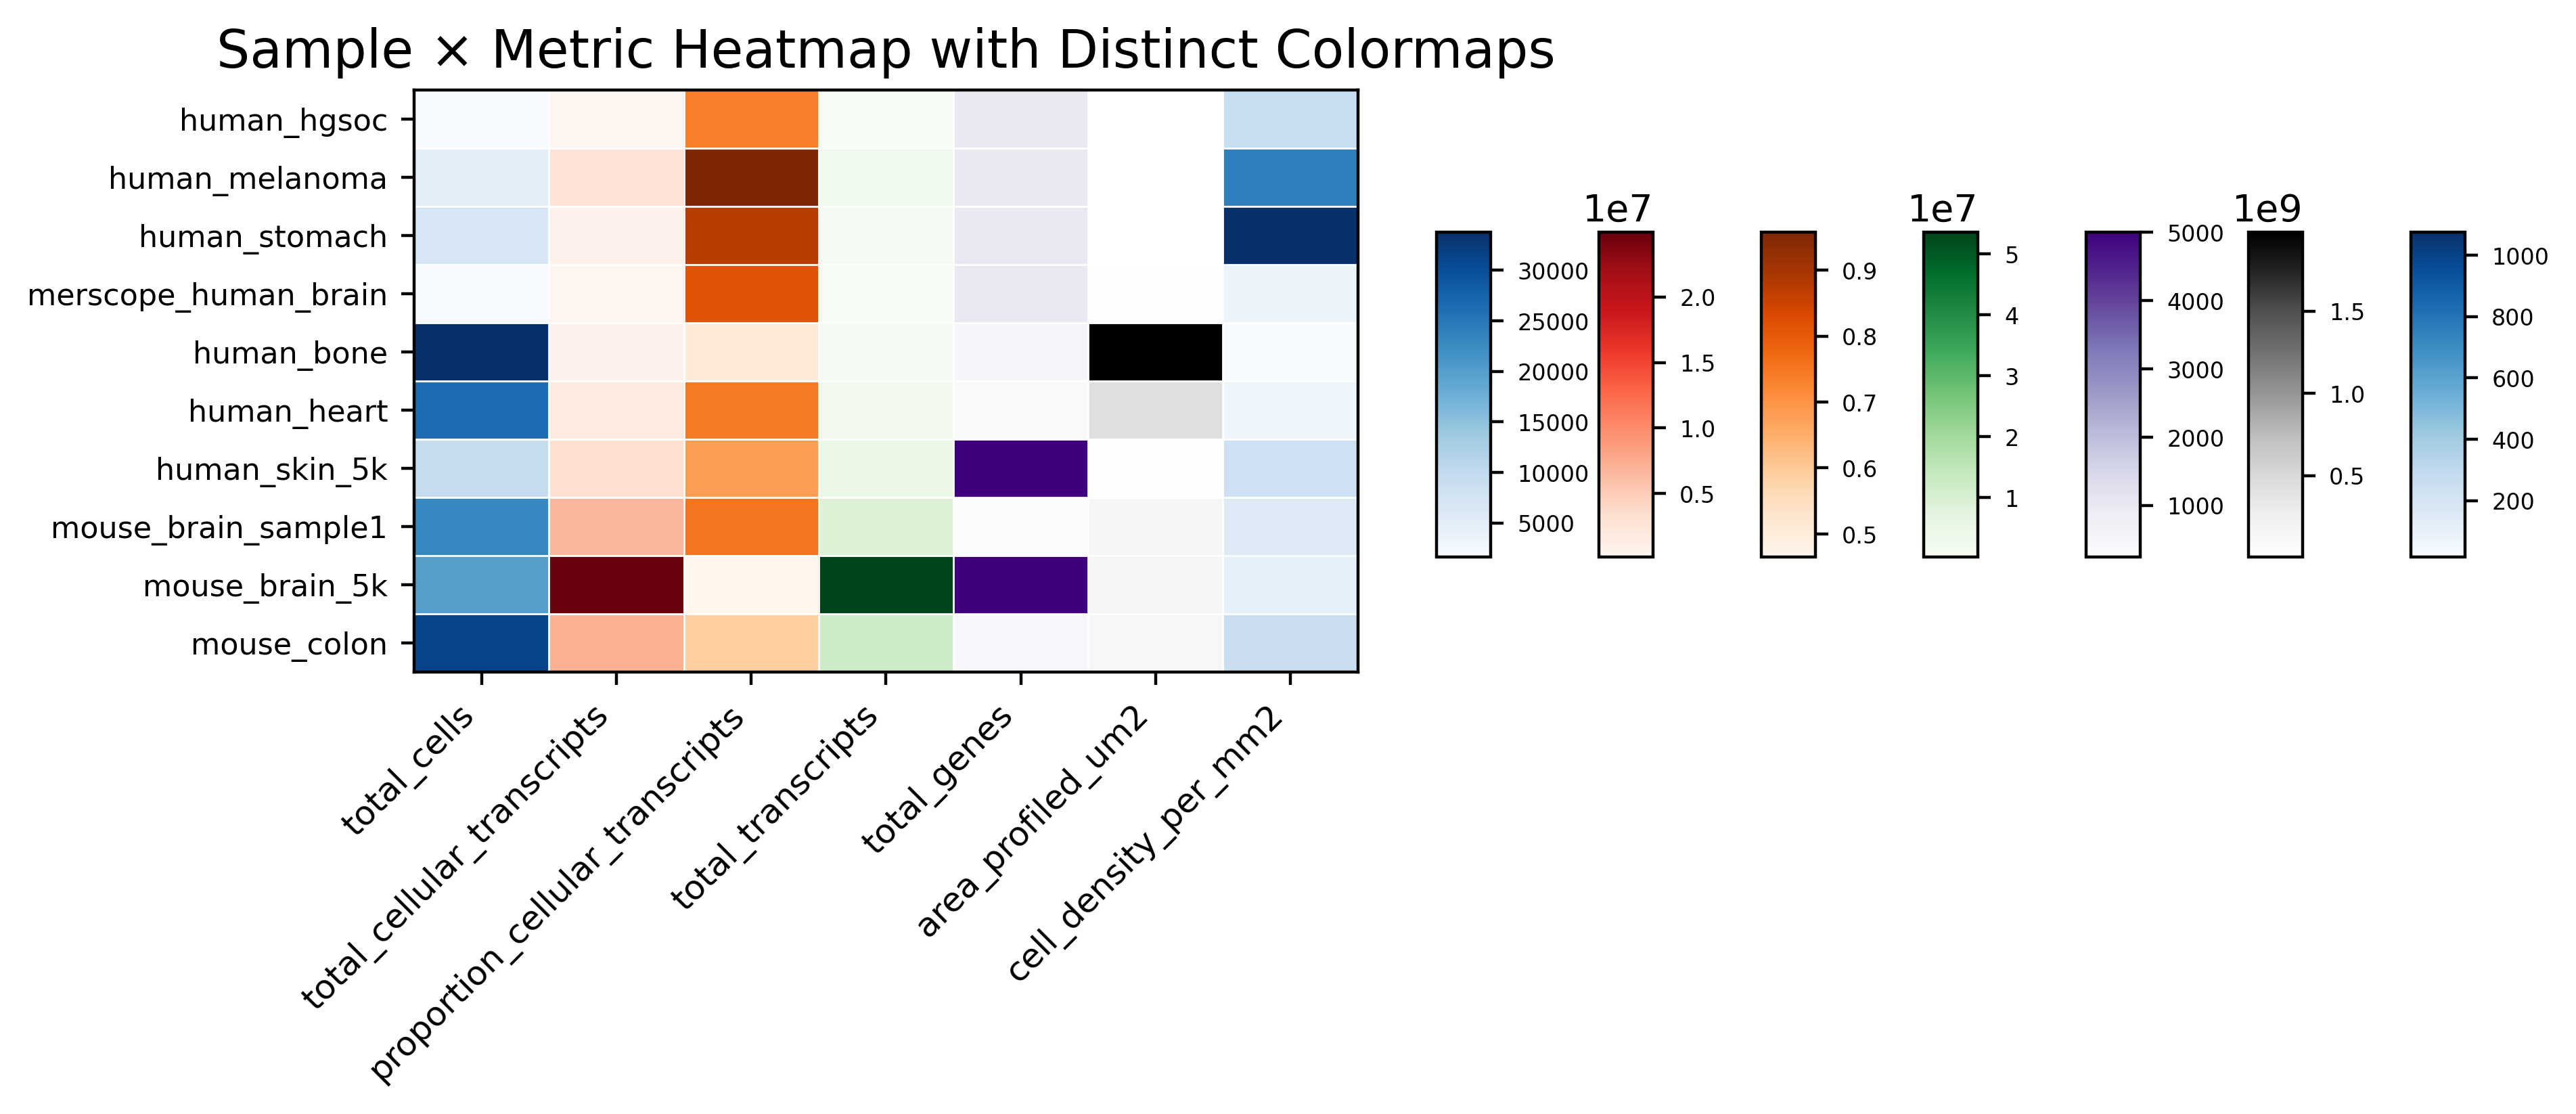

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from sklearn.preprocessing import MinMaxScaler

# Load your combined metadata CSV (update the path as needed)
# combined_metadata = pd.read_csv('/media/sergio/Meninges/troutpy/rois/combined_metadata.csv', index_col=0)

# Metrics to include as columns
metrics = [
    "total_cells",
    "total_cellular_transcripts",
    "proportion_cellular_transcripts",
    "total_transcripts",
    "total_genes",
    "area_profiled_um2",
    "cell_density_per_mm2",
]

# Extract data matrix and sample labels
data = combined_metadata[metrics].values
samples = combined_metadata.index.tolist()
n_samples, n_metrics = data.shape

# Normalize each column independently to [0, 1]
scaler = MinMaxScaler()
norm_data = scaler.fit_transform(data)

# Define a distinct colormap for each metric
colormaps = [cm.Blues, cm.Reds, cm.Oranges, cm.Greens, cm.Purples, cm.Greys, cm.Blues]

# Build an RGB image array: shape = (n_samples, n_metrics, 3)
rgb_image = np.zeros((n_samples, n_metrics, 3))
for j, cmap in enumerate(colormaps):
    rgba = cmap(norm_data[:, j])
    rgb_image[:, j, :] = rgba[:, :3]  # drop alpha channel

# Plot the combined heatmap
fig, ax = plt.subplots(figsize=(5, max(4, n_samples * 0.3)), constrained_layout=True, dpi=400)
ax.imshow(rgb_image, aspect="auto")

# Set axis ticks and labels
ax.set_xticks(np.arange(n_metrics))
ax.set_xticklabels(metrics, rotation=45, ha="right", fontsize=9)
ax.set_yticks(np.arange(n_samples))
ax.set_yticklabels(samples, fontsize=8)

# Add thin white grid lines for readability
ax.set_xticks(np.arange(-0.5, n_metrics, 1), minor=True)
ax.set_yticks(np.arange(-0.5, n_samples, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=0.5)
ax.tick_params(which="minor", length=0)

# Add a vertical colorbar for each metric
for j, cmap in enumerate(colormaps):
    # Create a ScalarMappable for this metric's true range
    norm = plt.Normalize(vmin=data[:, j].min(), vmax=data[:, j].max())
    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])
    # Position each small cbar to the right of the j-th column
    left = 1.05 + j * 0.12
    cbar_ax = fig.add_axes([left, 0.5, 0.04, 0.3])
    cbar = plt.colorbar(sm, cax=cbar_ax)
    cbar.ax.tick_params(labelsize=6)

ax.set_title("Sample × Metric Heatmap with Distinct Colormaps", fontsize=14)
plt.show()

In [48]:
combined_metadata

,sample_id,species,technology,segmentation_method,roi_name,tissue,disease,total_cells,total_cellular_transcripts,proportion_cellular_transcripts,total_transcripts,total_genes,area_profiled_um2,cell_density_per_mm2
sample_id,,,,,,,,,,,,,,
human_hgsoc,human_hgsoc,Hommo Sapiens,CosMx,cosmx-default,roi_hs_hgsoc,Ovary,serous ovarian carcinoma,1653,184297,0.733617,251217,979,6.291790e+06,262.723325
human_melanoma,human_melanoma,Hommo Sapiens,CosMx,cosmx-default,roi_hs_melanoma,skin,melanoma,4754,2915880,0.957969,3043815,987,6.329515e+06,751.084361
human_stomach,human_stomach,Hommo Sapiens,CosMx,cosmx-default,roi_hs_stomach,stomach,None,6826,746527,0.874159,853995,979,6.346376e+06,1075.574433
merscope_human_brain,merscope_human_brain,Homo Sapiens,MERSCOPE,MERSCOPE,brain_ROI,brain,alzheimer,1707,248383,0.814237,305050,960,2.112012e+07,80.823413
human_bone,human_bone,Homo Sapiens,Xenium,nuclei_expanded,human_bone,bone,control,33801,685345,0.508524,1347715,477,1.981349e+09,17.059589
human_heart,human_heart,Homo Sapiens,Xenium,nuclei_expanded,human_heart,heart,control,26366,1822577,0.743464,2451466,377,4.307469e+08,61.209952
human_skin_5k,human_skin_5k,Homo Sapiens,Xenium,multimodal,skin,skin,melanoma,9561,3165123,0.681547,4644030,5006,4.093351e+07,233.573897
mouse_brain_sample1,mouse_brain_sample1,Mus musculus,Xenium,nuclei_expanded,cortex_ROI,brain,control,23064,6713938,0.753784,8906974,248,1.524309e+08,151.307878
mouse_brain_5k,mouse_brain_5k,Mus musculus,Xenium,multimodal,cortex_ROI_2,brain,control,19836,24951252,0.465391,53613510,5006,1.715599e+08,115.621414


In [50]:
combined_metadata["cell_density_per_mm2"].sort_values()

sample_id
human_bone                17.059589
human_heart               61.209952
merscope_human_brain      80.823413
mouse_brain_5k           115.621414
mouse_brain_sample1      151.307878
human_skin_5k            233.573897
mouse_colon              254.803290
human_hgsoc              262.723325
human_melanoma           751.084361
human_stomach           1075.574433
Name: cell_density_per_mm2, dtype: float64

In [47]:
combined_metadata["area_profiled_um2"].sort_values()

sample_id
human_hgsoc             6.291790e+06
human_melanoma          6.329515e+06
human_stomach           6.346376e+06
merscope_human_brain    2.112012e+07
human_skin_5k           4.093351e+07
mouse_colon             1.224906e+08
mouse_brain_sample1     1.524309e+08
mouse_brain_5k          1.715599e+08
human_heart             4.307469e+08
human_bone              1.981349e+09
Name: area_profiled_um2, dtype: float64

In [76]:
combined_metadata

,sample_id,species,technology,segmentation_method,roi_name,tissue,disease,total_cells,total_cellular_transcripts,proportion_cellular_transcripts,total_transcripts,total_genes,area_profiled_um2,cell_density_per_mm2
sample_id,,,,,,,,,,,,,,
human_hgsoc,human_hgsoc,Hommo Sapiens,CosMx,cosmx-default,roi_hs_hgsoc,Ovary,serous ovarian carcinoma,1653,184297,0.733617,251217,979,6.291790e+06,262.723325
human_melanoma,human_melanoma,Hommo Sapiens,CosMx,cosmx-default,roi_hs_melanoma,skin,melanoma,4754,2915880,0.957969,3043815,987,6.329515e+06,751.084361
human_stomach,human_stomach,Hommo Sapiens,CosMx,cosmx-default,roi_hs_stomach,stomach,None,6826,746527,0.874159,853995,979,6.346376e+06,1075.574433
merscope_human_brain,merscope_human_brain,Homo Sapiens,MERSCOPE,MERSCOPE,brain_ROI,brain,alzheimer,1707,248383,0.814237,305050,960,2.112012e+07,80.823413
human_bone,human_bone,Homo Sapiens,Xenium,nuclei_expanded,human_bone,bone,control,33801,685345,0.508524,1347715,477,1.981349e+09,17.059589
human_heart,human_heart,Homo Sapiens,Xenium,nuclei_expanded,human_heart,heart,control,26366,1822577,0.743464,2451466,377,4.307469e+08,61.209952
human_skin_5k,human_skin_5k,Homo Sapiens,Xenium,multimodal,skin,skin,melanoma,9561,3165123,0.681547,4644030,5006,4.093351e+07,233.573897
mouse_brain_sample1,mouse_brain_sample1,Mus musculus,Xenium,nuclei_expanded,cortex_ROI,brain,control,23064,6713938,0.753784,8906974,248,1.524309e+08,151.307878
mouse_brain_5k,mouse_brain_5k,Mus musculus,Xenium,multimodal,cortex_ROI_2,brain,control,19836,24951252,0.465391,53613510,5006,1.715599e+08,115.621414


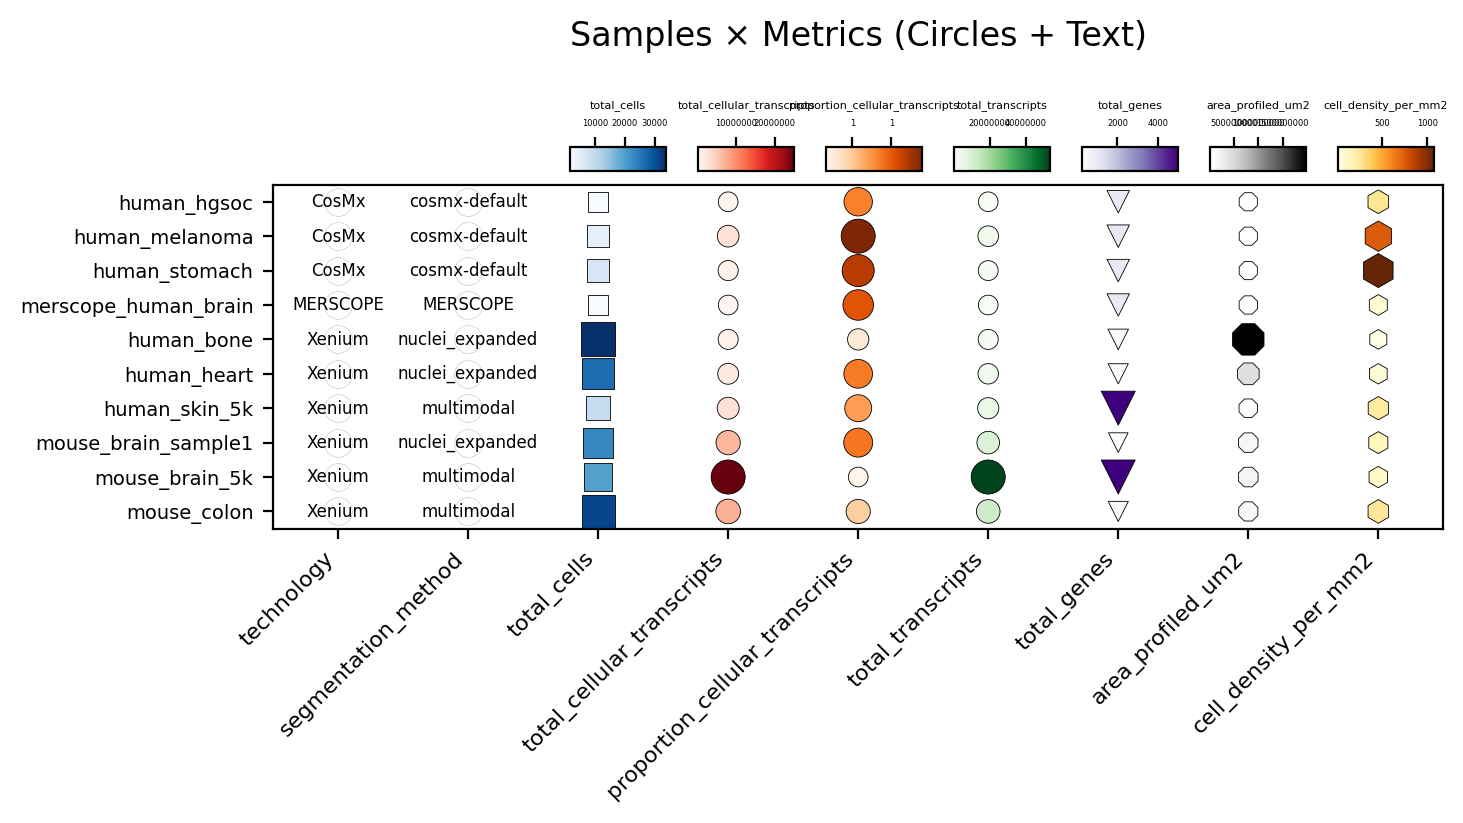

In [116]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from sklearn.preprocessing import MinMaxScaler
from matplotlib import ticker

# ——————————————————————————————
# 1. Load & Prepare Data
# ——————————————————————————————

# Example: replace with your real CSV path

# Define which fields to show
text_cols = ["technology", "segmentation_method"]  # non-numeric columns
metric_cols = [
    "total_cells",
    "total_cellular_transcripts",
    "proportion_cellular_transcripts",
    "total_transcripts",
    "total_genes",
    "area_profiled_um2",
    "cell_density_per_mm2",
]

markers = ["o", "o", "s", "o", "o", "o", "v", "8", "h"]
all_cols = text_cols + metric_cols

df = combined_metadata[all_cols].copy()
n_samples, n_metrics = df.shape

# Normalize each numeric column to [0,1]
scaler = MinMaxScaler()
df_norm = df.copy()
df_norm[metric_cols] = scaler.fit_transform(df[metric_cols])


# ——————————————————————————————
# 2. Set Up Plot Grid
# ——————————————————————————————

fig, ax = plt.subplots(figsize=(0.8 * n_metrics, max(4, n_samples * 0.4)), dpi=200, constrained_layout=True)

# Scatter grid: one circle per (row, col)
# x positions = column indices, y positions = sample indices
xs = np.repeat(np.arange(n_metrics), n_samples)
ys = np.tile(np.arange(n_samples), n_metrics)

# ——————————————————————————————
# 3. Draw Circles for Text Columns
# ——————————————————————————————

# For text columns, we’ll draw uniform grey circles, then overlay text
for j, col in enumerate(text_cols):
    x = np.full(n_samples, j)
    y = np.arange(n_samples)
    ax.scatter(
        x,
        y,
        s=100,  # circle size
        facecolors="white",
        edgecolors="grey",
        linewidths=0.1,
        zorder=2,
    )
    for yi, txt in enumerate(df[col]):
        ax.text(j, yi, str(txt), ha="center", va="center", fontsize=6, color="k", zorder=3)

# ——————————————————————————————
# 4. Draw Colored Circles for Numeric Metrics
# ——————————————————————————————

# Assign a unique colormap to each metric column
colormaps = [cm.Blues, cm.Reds, cm.Oranges, cm.Greens, cm.Purples, cm.Greys, cm.YlOrBr]

# Plot circles sized & colored by normalized value
for j, col in enumerate(metric_cols, start=len(text_cols)):
    vals = df_norm[col]  # already 0–1 scaled
    cmap = colormaps[j - len(text_cols)]
    colors = cmap(vals)
    mark = markers[j]

    ax.scatter(
        np.full(n_samples, j),  # x pos
        np.arange(n_samples),  # y pos
        s=vals * 100 + 50,  # size roughly proportional
        facecolors=colors,
        edgecolors="k",
        linewidths=0.3,
        zorder=2,
        marker=mark,
    )

# ——————————————————————————————
# 5. Colorbars for Numeric Metrics
# ——————————————————————————————
for idx, col in enumerate(metric_cols, start=len(text_cols)):
    cmap = colormaps[idx - len(text_cols)]
    norm = plt.Normalize(vmin=df[col].min(), vmax=df[col].max())
    sm = cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])

    # place each tiny cbar above its column
    left = 0.21 + idx / n_metrics * 0.8
    cax = fig.add_axes([left, 0.8, 0.6 / n_metrics, 0.03])
    cbar = plt.colorbar(sm, cax=cax, orientation="horizontal", ticklocation="top")
    cbar.ax.xaxis.set_label_position("top")
    cbar.ax.xaxis.set_major_formatter(ticker.FormatStrFormatter("%.0f"))
    cbar.ax.set_xlabel(col, fontsize=4)
    cbar.ax.tick_params(labelsize=3)

# ——————————————————————————————
# 6. Final Tuning
# ——————————————————————————————

ax.set_xlim(-0.5, n_metrics - 0.5)
ax.set_ylim(n_samples - 0.5, -0.5)  # flip so first sample is on top

ax.set_xticks(np.arange(n_metrics))
ax.set_xticklabels(all_cols, rotation=45, ha="right", fontsize=8)
ax.set_yticks(np.arange(n_samples))
ax.set_yticklabels(df.index, fontsize=7)

# light grid
ax.set_xticks(np.arange(-0.5, n_metrics, 1), minor=True)
ax.set_yticks(np.arange(-0.5, n_samples, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=1)
ax.tick_params(which="minor", length=0)

ax.set_title("Samples × Metrics (Circles + Text)", fontsize=12, pad=50)
plt.show()

In [108]:
list(combined_metadata["tissue"])

['Ovary',
 'skin',
 'stomach',
 'brain',
 'bone',
 'heart',
 'skin',
 'brain',
 'brain',
 'colon']

In [ ]:
# Combine all metadata DataFrames
if metadata_list:
    combined_metadata = pd.concat(metadata_list, ignore_index=True)
    print("Combined metadata shape:", combined_metadata.shape)
else:
    print("No metadata.csv files found.")

In [24]:
import os
import pandas as pd

# Define base output directory
base_figures_dir = "/media/sergio/Meninges/troutpy/parameter_tuning/saisnsc/xenium_msbrain_5k/figures"

# Initialize lists to collect data
summary_list = []
xrna_metadata_list = []

# Iterate through each parameter folder
for param_suffix in os.listdir(base_figures_dir):
    folder_path = os.path.join(base_figures_dir, param_suffix)
    folder_path = os.path.join(folder_path, param_suffix)
    summary_path = os.path.join(folder_path, "pipeline_summary.csv")
    xrna_metadata_path = os.path.join(folder_path, "pipeline_xrna_metadata.csv")

    if os.path.isfile(summary_path) and os.path.isfile(xrna_metadata_path):
        # Read and annotate summary
        summary_df = pd.read_csv(summary_path)
        summary_df["param_set"] = param_suffix
        summary_list.append(summary_df)

        # Read and annotate xrna metadata
        xrna_df = pd.read_csv(xrna_metadata_path)
        proportion = xrna_df[["extracellular_proportion"]]
        proportion.columns = [param_suffix]
        xrna_metadata_list.append(proportion)

# Combine all
combined_summary = pd.concat(summary_list, ignore_index=True)
combined_xrna_metadata = pd.concat(xrna_metadata_list, axis=1)

##  Combine xrna proportions across runs

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd

# filter xrna metadata
combined_xrna_metadata = combined_xrna_metadata[np.sum(combined_xrna_metadata.isna(), axis=1) == 0]
# Compute cosine similarity between parameter sets (columns)
cos_sim_matrix = cosine_similarity(combined_xrna_metadata.T)
# Turn it into a labeled DataFrame
cos_sim_df = pd.DataFrame(cos_sim_matrix, index=combined_xrna_metadata.columns, columns=combined_xrna_metadata.columns)

<Figure size 600x500 with 0 Axes>

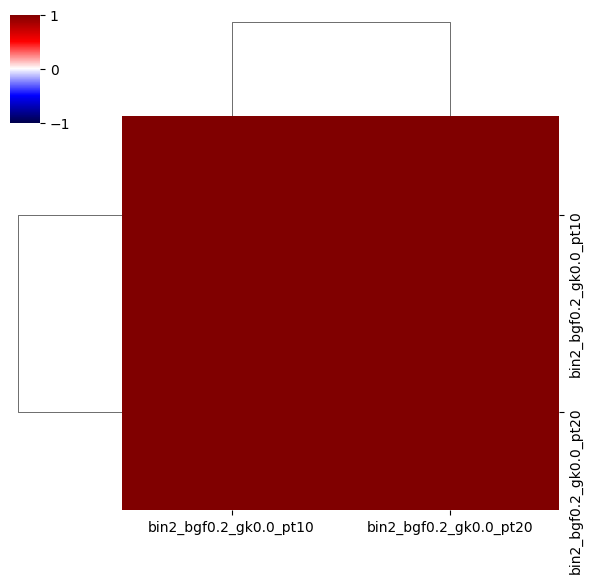

In [59]:
plt.figure(figsize=(6, 5))
sns.clustermap(
    cos_sim_df,
    vmin=-1,
    vmax=1,
    cmap="seismic",
    figsize=(6, 6),
)

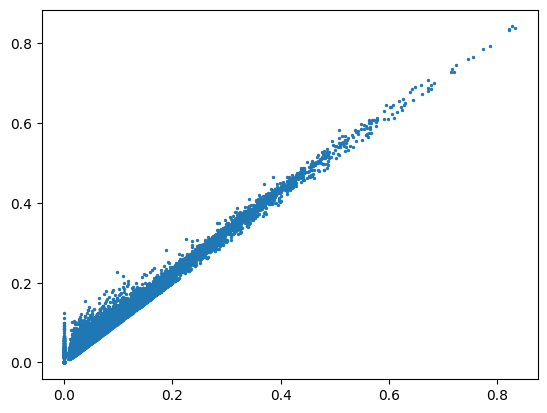

In [27]:
plt.scatter(combined_xrna_metadata.iloc[:, 0], combined_xrna_metadata.iloc[:, 1], s=2)

### Plot propotion of exRNA identified

In [ ]:
combined_summary["proportion_of_cell_like"] = (
    1 - combined_summary["proportion_of_segmented"] - combined_summary["proportion_of_extracellular"]
)
combined_summary.index = combined_summary["param_set"]
combined_summary.pop("param_set")

<Axes: ylabel='param_set'>

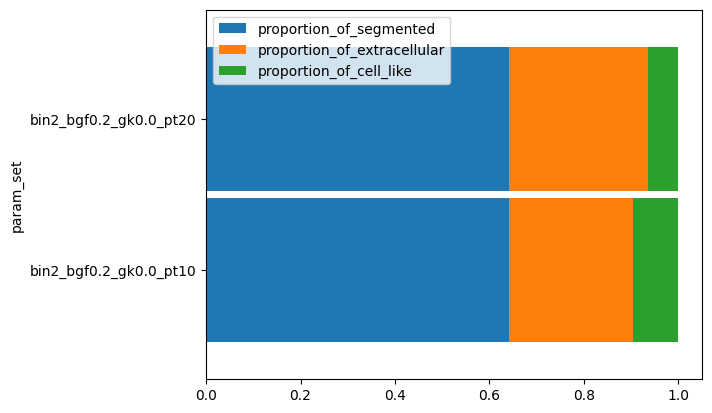

In [56]:
# plot combined summary as bar plot
combined_summary.plot(kind="barh", stacked=True, width=0.95)

In [ ]:
# Save if needed
combined_summary.to_csv("/media/sergio/Meninges/troutpy/parameter_tuning/combined_summary.csv", index=False)
combined_xrna_metadata.to_csv(
    "/media/sergio/Meninges/troutpy/parameter_tuning/combined_xrna_metadata.csv", index=False
)

print("Combined files saved.")